#

In [560]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Import Statsmodels
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tools.eval_measures import rmse, aic

In [783]:
df_vitals2 = pd.read_csv('vitals2.csv')

/home/ablew/anaconda3/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3049: DtypeWarning: Columns (0,1,4,9,10,11,22,27,28,29) have mixed types. Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [561]:
df_vitals = pd.read_csv('vitals_combined_interpolated.csv')
df_beta = pd.read_csv('beta-blocker-dosages.csv')

In [562]:
df_vitals.columns = ['patient_uuid', 'timestamp', 'batch', 'HR', 'SBP']

In [563]:
df_vitals.head()

,patient_uuid,timestamp,batch,HR,SBP
0,1127912,2019-11-19,0,87.261064,124.85394
1,1127912,2019-11-20,0,92.000000,120.50000
2,1127912,2019-11-21,0,87.000000,131.75000
3,1127912,2019-11-22,0,89.000000,127.00000
4,1127912,2019-11-23,0,93.000000,109.50000


In [711]:
df_vitals['timestamp'] = pd.to_datetime(df_vitals['timestamp'], errors='coerce')

df_vitals = df_vitals[['patient_uuid', 'timestamp', 'batch', 'HR', 'SBP']]

df_vitals = df_vitals[(df_vitals.timestamp >= '2018-10-01') & (df_vitals.timestamp <= '2020-01-14')]
df_vitals = df_vitals[~df_vitals['SBP'].isna()]
df_vitals = df_vitals[~df_vitals['HR'].isna()]

# columns with number of non-empty rows
(~df_vitals.isna()).sum() / len(df_vitals) * 100

patient_uuid    100.0
timestamp       100.0
batch           100.0
HR              100.0
SBP             100.0
dtype: float64

In [852]:
df_vitals2['timestamp'] = pd.to_datetime(df_vitals2['timestamp'], errors='coerce')

df_vitals2 = df_vitals2[['patient_uuid', 'timestamp', 'HR', 'SBP']]

df_vitals2 = df_vitals2[(df_vitals2.timestamp >= '2018-10-01') & (df_vitals2.timestamp <= '2020-01-14')]
df_vitals2 = df_vitals2[~df_vitals2['SBP'].isna()]
df_vitals2 = df_vitals2[~df_vitals2['HR'].isna()]

df_vitals2.head()

,patient_uuid,timestamp,HR,SBP
1,82591262,2018-10-09 13:40:00,80.0,111.0
2,82591262,2018-10-09 17:39:00,79.0,134.0
3,82591262,2018-10-09 17:40:00,79.0,126.0
4,82591262,2018-10-10 08:07:00,53.0,137.0
5,82591262,2018-10-10 14:02:00,71.0,134.0


In [853]:
df_vitals2 = df_vitals2.groupby([df_vitals2.patient_uuid, pd.Grouper(key='timestamp', freq='D')]).mean().reset_index()
df_vitals2.head()

,patient_uuid,timestamp,HR,SBP
0,1048697,2019-08-26,80.000000,126.000000
1,1048697,2019-08-27,92.666667,123.000000
2,1048697,2019-08-28,84.500000,113.000000
3,1048697,2019-08-29,84.333333,125.333333
4,1048697,2019-08-30,91.500000,122.000000


In [568]:
# Drops batches containing less than 30 observations.
df_recordings_per_patient = df_vitals.groupby(['patient_uuid', 'batch']).count().reset_index()
low_batches = df_recordings_per_patient[(df_recordings_per_patient.HR <= 30)][['patient_uuid','batch']]

for i in range(len(low_batches)):
    low_patient = low_batches.patient_uuid.iloc[i]
    low_batch = low_batches.batch.iloc[i]
    df_vitals.drop(df_vitals[(df_vitals.patient_uuid == low_patient) & (df_vitals.batch == low_batch)].index, inplace=True)

In [963]:
idx = df_vitals.groupby(['patient_uuid'])['batch'].transform(max) == df_vitals['batch']
df_vitals = df_vitals[idx]

In [570]:
# Creates patient list based on the cleaned dataframe.
patients = df_vitals.patient_uuid.unique()

In [787]:
df_vitals2[df_vitals2.patient_uuid == 19441941][['patient_uuid', 'timestamp', 'HR', 'SBP']].tail()

,patient_uuid,timestamp,HR,SBP
262836,19441941,1/10/20 5:23 AM,82.0,117.0
262837,19441941,1/11/20 6:33 AM,83.0,124.0
262838,19441941,1/12/20 6:40 AM,83.0,125.0
262839,19441941,1/13/20 6:04 AM,73.0,125.0
262840,19441941,1/14/20 6:34 AM,87.0,135.0


In [796]:
# Creates a temporary time series for a patient for testing functions and debugging.
df_temp1 = df_vitals[df_vitals.patient_uuid == 19441941] #73939445, 36279955, 62596157, 19441941
df_temp1.index = pd.DatetimeIndex(df_temp1.timestamp).to_period('D')
df_temp1 = df_temp1[['patient_uuid','timestamp','HR','SBP']].copy()
df_temp1.tail()

,patient_uuid,timestamp,HR,SBP
timestamp,,,,
2020-01-08,19441941,2020-01-08,80.800357,127.089801
2020-01-09,19441941,2020-01-09,80.851330,126.796591
2020-01-10,19441941,2020-01-10,80.902304,126.503380
2020-01-11,19441941,2020-01-11,80.953277,126.210169
2020-01-12,19441941,2020-01-12,81.004250,125.916958


In [794]:
df_vitals[df_vitals.patient_uuid == 73939445].tail()

,patient_uuid,timestamp,batch,HR,SBP
95967,73939445,2020-01-08,0,84.762363,134.271408
95968,73939445,2020-01-09,0,84.733309,134.197436
95969,73939445,2020-01-10,0,84.704254,134.123464
95970,73939445,2020-01-11,0,84.675200,134.049492
95971,73939445,2020-01-12,0,84.646146,133.975519


In [795]:
df_vitals2[df_vitals2.patient_uuid == 73939445][['patient_uuid','timestamp','HR','SBP']].tail()

,patient_uuid,timestamp,HR,SBP
191413,73939445,1/8/20 12:33 PM,95.0,124.0
191414,73939445,1/9/20 10:58 AM,87.0,102.0
191415,73939445,1/11/20 4:12 PM,80.0,113.0
191416,73939445,1/13/20 4:30 PM,90.0,133.0
191417,73939445,1/14/20 2:44 PM,81.0,130.0


In [487]:
from statsmodels.tsa.stattools import grangercausalitytests
maxlag=12
test = 'ssr_chi2test'
def grangers_causation_matrix(data, variables, test='ssr_chi2test', verbose=False):    
    """Check Granger Causality of all possible combinations of the Time series.
    The rows are the response variable, columns are predictors. The values in the table 
    are the P-Values. P-Values lesser than the significance level (0.05), implies 
    the Null Hypothesis that the coefficients of the corresponding past values is 
    zero, that is, the X does not cause Y can be rejected.

    data     : pandas dataframe containing the time series variables
    variables: list containing names of the time series variables.
    
    output   : dataframe containing p-values to test causation.
    """
    df = pd.DataFrame(np.zeros((len(variables), len(variables))), columns=variables, index=variables)
    for c in df.columns:
        for r in df.index:
            test_result = grangercausalitytests(data[[r, c]], maxlag=maxlag, verbose=False)
            p_values = [round(test_result[i+1][0][test][1],4) for i in range(maxlag)]
            if verbose: print(f'Y = {r}, X = {c}, P Values = {p_values}')
            min_p_value = np.min(p_values)
            df.loc[r, c] = min_p_value
    df.columns = [var + '_x' for var in variables]
    df.index = [var + '_y' for var in variables]
    return df



In [765]:
grangers_causation_matrix(df_temp1, variables = df_temp1.columns)

,HR_x,SBP_x
HR_y,1.0,0.0
SBP_y,0.0,1.0


In [362]:
from statsmodels.tsa.vector_ar.vecm import coint_johansen

def cointegration_test(df, alpha=0.05): 
    """
    Perform Johanson's Cointegration Test and Report Summary.
    
    df    : time series dataframe for a particular patient.
    
    output: prints summary of the results of the cointegration test.
    """
    out = coint_johansen(df,-1,5)
    d = {'0.90':0, '0.95':1, '0.99':2}
    traces = out.lr1
    cvts = out.cvt[:, d[str(1-alpha)]]
    def adjust(val, length= 6): return str(val).ljust(length)

    # Summary
    print('Name   ::  Test Stat > C(95%)    =>   Signif  \n', '--'*20)
    for col, trace, cvt in zip(df.columns, traces, cvts):
        print(adjust(col), ':: ', adjust(round(trace,2), 9), ">", adjust(cvt, 8), ' =>  ' , trace > cvt)



In [766]:
cointegration_test(df_temp1)

Name   ::  Test Stat > C(95%)    =>   Signif  
 ----------------------------------------
HR     ::  19.17     > 12.3212   =>   True
SBP    ::  0.0       > 4.1296    =>   False


In [767]:
nobs = 7
df_train, df_test = df_temp1[0:-nobs], df_temp1[-nobs:]

In [491]:
def adfuller_test(series, signif=0.05, name='', verbose=False):
    """
    Performs ADFuller to test for Stationarity of given series and prints report.
    
    series: pandas series of the feature to test stationarity on.
    
    output: True if stationary, False if not stationary.
    
    """
    r = adfuller(series, autolag='AIC')
    p_value = round(r[1], 4)

    if p_value <= signif:
        is_stationary = True
    else:
        is_stationary = False
        
    return is_stationary

In [768]:
# ADF Test on each column
for name, column in df_train.iteritems():
    print(adfuller_test(column, name=column.name))
    

False
False


In [769]:
# Differenced time series since HR is not stationary.
df_differenced = df_train.diff().dropna()
df_differenced.head()

,HR,SBP
timestamp,,
2019-10-30,3.232238,18.614566
2019-10-31,0.050973,-0.293211
2019-11-01,0.050973,-0.293211
2019-11-02,0.050973,-0.293211
2019-11-03,0.050973,-0.293211


In [770]:
# ADF Test on each column
for name, column in df_differenced.iteritems():
    print(adfuller_test(column, name=column.name))

True
True


In [775]:
# fits model based on the order that yields the lowest AIC and prints summary.
model = VAR(df_differenced)
x = model.select_order(maxlags=20)
lag_order = 7
model_fitted = model.fit(lag_order)
model_fitted.summary()

/home/ablew/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/vector_ar/var_model.py:1387: RuntimeWarning: invalid value encountered in sqrt
  stderr = np.sqrt(np.diag(self.cov_params))
/home/ablew/anaconda3/lib/python3.7/site-packages/scipy/stats/_distn_infrastructure.py:877: RuntimeWarning: invalid value encountered in greater
  return (self.a < x) & (x < self.b)
/home/ablew/anaconda3/lib/python3.7/site-packages/scipy/stats/_distn_infrastructure.py:877: RuntimeWarning: invalid value encountered in less
  return (self.a < x) & (x < self.b)
/home/ablew/anaconda3/lib/python3.7/site-packages/scipy/stats/_distn_infrastructure.py:1831: RuntimeWarning: invalid value encountered in less_equal
  cond2 = cond0 & (x <= self.a)


  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Wed, 04, Mar, 2020
Time:                     07:38:40
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -10.2263
Nobs:                     61.0000    HQIC:                  -10.8576
Log likelihood:           200.456    FPE:                1.30871e-05
AIC:                     -11.2645    Det(Omega_mle):     8.43093e-06
--------------------------------------------------------------------
Results for equation HR
                  coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------------
const    1352103110448.042725              NAN              NAN             NAN
L1.HR    2903284475291.610352   4199039.650662       691416.304           0.000
L1.SBP   2052262036049.036133   3059494.903680       670784.590    

Performs the durbin watson statistic to check for serial correlation of residuals to ensure that the model is able to explain the variances and patterns in the time series.
The value of this statistic can vary between 0 and 4. The closer it is to the value 2, then there is no significant serial correlation. The closer to 0, there is a positive serial correlation, and the closer it is to 4 implies negative serial correlation.

In [776]:
from statsmodels.stats.stattools import durbin_watson
out = durbin_watson(model_fitted.resid)

for col, val in zip(df_temp1.columns, out):
    print(col, ':', round(val, 2))

HR : 2.02
SBP : 2.02


In [789]:
df_train.tail()

,HR,SBP
timestamp,,
2020-01-01,80.443545,129.142278
2020-01-02,80.494518,128.849067
2020-01-03,80.545492,128.555856
2020-01-04,80.596465,128.262645
2020-01-05,80.647438,127.969434


In [782]:
df_train.diff().tail()

,HR,SBP
timestamp,,
2020-01-01,0.050973,-0.293211
2020-01-02,0.050973,-0.293211
2020-01-03,0.050973,-0.293211
2020-01-04,0.050973,-0.293211
2020-01-05,0.050973,-0.293211


In [777]:
# Input data for forecasting
#forecast_input = df_train.values[-lag_order:]
forecast_input = df_differenced.values[-lag_order:]
forecast_input

array([[ 0.05097314, -0.29321092],
       [ 0.05097314, -0.29321092],
       [ 0.05097314, -0.29321092],
       [ 0.05097314, -0.29321092],
       [ 0.05097314, -0.29321092],
       [ 0.05097314, -0.29321092],
       [ 0.05097314, -0.29321092]])

In [778]:
# Forecast
fc = model_fitted.forecast(y=forecast_input, steps=nobs)
df_forecast = pd.DataFrame(fc, index=df_temp1.index[-nobs:], columns=df_temp1.columns + '_forecast')
df_forecast

,HR_forecast,SBP_forecast
timestamp,,
2020-01-06,-1.377221e-01,-2.619516e-02
2020-01-07,1.503222e+08,-2.126571e+08
2020-01-08,7.094077e+08,-1.003953e+09
2020-01-09,-7.614387e+17,1.077189e+18
2020-01-10,-3.552901e+18,5.027785e+18
2020-01-11,3.250394e+27,-4.598252e+27
2020-01-12,1.825684e+28,-2.583418e+28


In [345]:
def invert_transformation(df_train, df_forecast, second_diff=False):
    """
    Revert back the differencing to get the forecast to original scale.
    
    df_train   : training set of the timeseries for a particular patient.
    df_forecast: forecast of the timeseries for a particular patient.
    
    output     : forecast dataframe with its values converted to its original scale.
    """
    df_fc = df_forecast.copy()
    columns = df_train.columns
    for col in columns:        
        # Roll back 2nd Diff
        if second_diff:
            df_fc[str(col) + '_forecast'] = (df_train[col].iloc[-1]-df_train[col].iloc[-2]) + df_fc[str(col)+'_forecast'].cumsum()
        # Roll back 1st Diff
        df_fc[str(col) + '_forecast'] = df_train[col].iloc[-1] + df_fc[str(col)+'_forecast'].cumsum()
    return df_fc

In [779]:
df_forecast = invert_transformation(df_train, df_forecast, second_diff=False)

In [780]:
df_forecast

,HR_forecast,SBP_forecast
timestamp,,
2020-01-06,8.050972e+01,1.279432e+02
2020-01-07,1.503223e+08,-2.126570e+08
2020-01-08,8.597300e+08,-1.216610e+09
2020-01-09,-7.614387e+17,1.077189e+18
2020-01-10,-4.314339e+18,6.104973e+18
2020-01-11,3.250394e+27,-4.598252e+27
2020-01-12,2.150723e+28,-3.043243e+28


In [502]:
def forecast_accuracy(forecast, actual):
    """
    Calculates accuracy by calculating mean absolute percentage error, mean absolute error, 
    and root-mean-squared error.
    
    forecast: forecast dataframe containing the results from a model.
    actual  : test set of a particular patient, with same dates as the forecast dataframe.
    
    output  : mape: mean absolute percentage error
              mae : mean absolute error
              rsme: root mean square error
    """
    forecast = forecast.values
    mape = np.mean(np.abs(forecast - actual)/np.abs(actual))  # MAPE
    mae = np.mean(np.abs(forecast - actual))    # MAE
    rmse = np.mean((forecast - actual)**2)**.5  # RMSE
    return mape, mae, rmse

In [880]:
def var_model(patient):
    """
    Creates train and test sets for a particular patient, runs adfuller test to check stationarity, 
    differentiates dataframe if not stationary, fits model, and creates a forecast (to compare with test set), 
    and a future dataframe containing the predicted values for the dates following the test set.
    
    patient: patient uuid
    
    output : df_train2  : copy of the training set for a particular patient.
             df_test    : test set for a particular patient.
             df_forecast: forecasted values to compare with test set.
             df_future  : predicted values for future dates.
    """
    nobs = 7
    diff = 0
    max_diff = 2
    
    df_patient = df_vitals[df_vitals.patient_uuid == patient]
    df_patient
    
    df_patient.index = pd.DatetimeIndex(df_patient.timestamp).to_period('D')
    df_patient = df_patient[['HR','SBP']].copy()
    df_patient2 = df_patient.copy()
    
    df_train, df_test = df_patient[0:-nobs], df_patient[-nobs:]
    df_train2 = df_train.copy()
    

    are_stationary = []
    for name, column in df_train.iteritems():
        are_stationary.append(adfuller_test(column, name=column.name))
        
    while (all(are_stationary) == False) and (diff < max_diff):
        are_stationary = []
        df_train = df_train.diff().dropna()
        df_patient = df_patient.diff().dropna()
        for name, column in df_train.iteritems():
            are_stationary.append(adfuller_test(column, name=column.name))

        diff += 1

    
    model = VAR(df_train)
    lag_order = model.select_order(maxlags=20).aic
    if lag_order == 0:
        lag_order = 7
    model_fitted = model.fit(lag_order)
    forecast_input = df_train.values[-lag_order:]
    future_input = df_patient.values[-lag_order:]
    
    fc = model_fitted.forecast(y=forecast_input, steps=nobs)
    fc2 = model_fitted.forecast(y=future_input, steps=nobs)
    
    df_forecast = pd.DataFrame(fc, index=df_patient.index[-nobs:], columns=df_patient.columns + '_forecast')
    df_future = pd.DataFrame(fc2, index=df_patient[-nobs:].index + 7, columns = df_patient.columns + '_forecast')
    
    if diff == 1:
        df_forecast = invert_transformation(df_train2, df_forecast, second_diff=False)
        df_future = invert_transformation(df_patient2, df_future, second_diff=False)
    elif diff == 2:
        df_forecast = invert_transformation(df_train2, df_forecast, second_diff=True)
        df_future = invert_transformation(df_patient2, df_future, second_diff=True)
        
    return  df_train2, df_test, df_forecast, df_future
        
        
        

In [964]:
df_train, df_test, df_forecast, df_future = var_model(36279955) # 73939445, 36279955

In [965]:
a = forecast_accuracy(df_forecast, df_test)
a

(HR     0.074929
 SBP    0.057111
 dtype: float64, HR     6.088756
 SBP    7.926078
 dtype: float64, HR     7.597279
 SBP    9.066859
 dtype: float64)

In [966]:
df_vitals[df_vitals.patient_uuid == patients_over_30[7]].tail(10)

,patient_uuid,timestamp,batch,HR,SBP
693,2075791,2019-11-28,0,50.500000,132.500000
694,2075791,2019-11-29,0,53.822345,128.025691
695,2075791,2019-11-30,0,49.500000,128.000000
696,2075791,2019-12-01,0,53.082828,127.983895
697,2075791,2019-12-02,0,52.713070,127.962997
698,2075791,2019-12-03,0,52.343312,127.942099
699,2075791,2019-12-04,0,53.000000,126.000000
700,2075791,2019-12-05,0,56.500000,130.500000
701,2075791,2019-12-06,0,50.666667,122.666667
702,2075791,2019-12-07,0,52.500000,132.500000


In [527]:
# Runs VAR model on all patients and collects data on accuracy.
HR_mape = []
HR_mae = []
HR_rsme = []
SBP_mape = []
SBP_mae = []
SBP_rsme = []

for patient in patients:
    results_train, results_test, results_forecast, results_future = var_model(patient)
    accuracy_indicators = forecast_accuracy(results_forecast, results_test)
    
    HR_mape.append(accuracy_indicators[0][0])
    HR_mae.append(accuracy_indicators[1][0])
    HR_rsme.append(accuracy_indicators[2][0])
    SBP_mape.append(accuracy_indicators[0][1])
    SBP_mae.append(accuracy_indicators[1][1])
    SBP_rsme.append(accuracy_indicators[2][1])

In [581]:
# Creates and populates dataframe containing data on accuracy of the models for each patient.
df_model = pd.DataFrame(columns = ['patient_uuid', 'HR_mape', 'HR_mae', 'HR_rsme', 'SBP_mape', 'SBP_mae', 'SBP_rsme'])
df_model.patient_uuid = patients
df_model.HR_mape = HR_mape
df_model.HR_mae = HR_mae
df_model.HR_rsme = HR_rsme
df_model.SBP_mape = SBP_mape
df_model.SBP_mae = SBP_mae
df_model.SBP_rsme = SBP_rsme

df_model.head()

,patient_uuid,HR_mape,HR_mae,HR_rsme,SBP_mape,SBP_mae,SBP_rsme
0,1127912,0.056662,5.166311,6.590516,0.042878,5.674134,6.527898
1,1164638,0.015971,1.250469,1.912734,0.016423,1.935242,3.428934
2,1166047,0.114683,7.911892,8.068932,0.126569,14.273312,15.166446
3,1193821,0.029995,1.925800,2.473920,0.103789,11.870040,13.675413
4,1231804,0.065583,5.092933,5.246183,0.126942,14.963018,18.015287


In [738]:
df_vitals[df_vitals.patient_uuid == 19441941]

,patient_uuid,timestamp,batch,HR,SBP
22784,19441941,2019-10-29,0,74.000000,129.000000
22785,19441941,2019-10-30,0,77.232238,147.614566
22786,19441941,2019-10-31,0,77.283211,147.321355
22787,19441941,2019-11-01,0,77.334184,147.028144
22788,19441941,2019-11-02,0,77.385157,146.734933
22789,19441941,2019-11-03,0,77.436130,146.441722
22790,19441941,2019-11-04,0,77.487103,146.148511
22791,19441941,2019-11-05,0,77.538076,145.855300
22792,19441941,2019-11-06,0,77.589050,145.562090
22793,19441941,2019-11-07,0,77.640023,145.268879


In [967]:
a,b,c,d = var_model(19441941)
c

,HR_forecast,SBP_forecast
timestamp,,
2020-01-06,8.050972e+01,1.279432e+02
2020-01-07,1.503223e+08,-2.126570e+08
2020-01-08,8.597300e+08,-1.216610e+09
2020-01-09,-7.614387e+17,1.077189e+18
2020-01-10,-4.314339e+18,6.104973e+18
2020-01-11,3.250394e+27,-4.598252e+27
2020-01-12,2.150723e+28,-3.043243e+28


In [1054]:
a.diff().dropna().tail(15)

,HR,SBP
timestamp,,
2019-12-22,0.050973,-0.293211
2019-12-23,0.050973,-0.293211
2019-12-24,0.050973,-0.293211
2019-12-25,0.050973,-0.293211
2019-12-26,0.050973,-0.293211
2019-12-27,0.050973,-0.293211
2019-12-28,0.050973,-0.293211
2019-12-29,0.050973,-0.293211
2019-12-30,0.050973,-0.293211


In [551]:
df_model.to_csv('models_stats.csv', index=False)

### Flag-raising algorithm

HR changes 

rising 10 bpm

strict rule bpm > 100; (BPM <55 +/- symptoms)
	
    
BP rising /falling 

		Rising >5mm/30 days
        
		Strict rule 180 mm SBP / under 90mm SBP
        
		Goal is <140mm Hg
        

In [531]:
#df_train, df_test, df_forecast,df_future = var_model(patients_over_30[81])
current = df_train[-23:]
future = df_test
forecast = df_forecast
forecast.columns = ['HR','SBP']
actual = pd.concat([current, future])
pred = pd.concat([current, forecast])

Prediction of need of blood pressure medication or beta blocker medication titration (rule-based):
HR changes 

HR rising/falling  >10bpm/30 days

Strict rule bpm over 100 bpm HR / under 55 bpm HR 
	

BP changes

BP rising /falling  >5mm/30 days

Strict rule 180 mm SBP / under 90mm SBP

Goal is <140mm Hg

In [663]:
def flags(df, report=False):
    """
    Flag-raising algorithm based on health deterioration rules.
    
    df    : 30-day timeseries pandas dataframe.
    report: True if written report requested. False if status of each flag is wanted.
    
    output: returns a list containing the average value of HR and SBP during the last ten days of the time series,
            and the different flags that are raised based on the conditions above.
    """
    rising_HR = False
    lowering_HR = False
    rising_SBP = False
    high_BP = False
    
    first_ten = np.mean(df[:10])
    last_ten = np.mean(df[-10:])

    deltas = (last_ten - first_ten)
    
    if deltas[0] >= 10:
        rising_HR = True
        flag_message_1 = 'Detected rising heart rate. \n'
    elif deltas[0] <= -10:
        lowering_HR = True
        flag_message_1 = 'Detected decreasing heart rate. \n'
    else:
        flag_message_1 = 'No changes in heart rate detected. \n'
        
    if deltas[1] >= 5:
        rising_SBP = True
        flag_message_2 = 'Detected rising blood pressure (SBP). \n'
    else:
        flag_message_2 = 'No changes in blood pressure detected. \n'

    min_HR = np.sum(df.HR < 55)
    max_HR = np.sum(df.HR > 100)

    min_SBP = np.sum(df.SBP < 90)
    max_SBP = np.sum(df.SBP > 180)
    
    flag_message_3 = 'Heart rate lower than 55 bpm detected ' + str(min_HR) + ' times. \n'
    flag_message_4 = 'Heart rate greater than 100 bpm detected ' + str(max_HR) + ' times. \n'
    flag_message_5 = 'Systolic blood pressure (SBP) lower than 90 bpm detected ' + str(min_SBP) + ' times. \n'
    flag_message_6 = 'Systolic blood pressure (SBP) greater than 180 bpm detected ' + str(max_SBP) + ' times. \n'
    flag_message_7 = ''
    
    high_SBP = (df.SBP > 140)
    
    if np.sum(high_SBP[-15:]) > 7:
        high_BP = True
        flag_message_7 = 'High blood pressure detected.'
    if report == True:
        if high_BP == True:
            message = flag_message_1 + flag_message_2 + flag_message_3 + flag_message_4 + flag_message_5 + flag_message_6 + flag_message_7 
        else:
            message = flag_message_1 + flag_message_2 + flag_message_3 + flag_message_4 + flag_message_5 + flag_message_6
        print(message)
    else:
        return [last_ten, rising_HR, lowering_HR, rising_SBP, min_HR, max_HR, min_SBP, max_SBP, high_BP]

In [588]:
flags(actual, report=True)

No changes in heart rate detected. 
No changes in blood pressure detected. 
Heart rate lower than 55 bpm detected 0 times. 
Heart rate greater than 100 bpm detected 0 times. 
Systolic blood pressure (SBP) lower than 90 bpm detected 0 times. 
Systolic blood pressure (SBP) greater than 180 bpm detected 0 times. 



In [589]:
flags(pred)

[HR      72.857331
 SBP    138.248167
 dtype: float64, HR      72.419021
 SBP    136.299374
 dtype: float64, False, False, False, 0, 0, 0, 0, False]

In [810]:
def compare_flags(df_train, df_test, df_forecast):
    """
    Compares the results of the flag-raising algorithm.
    
    df_train   : training set of the timeseries for a particular patient.
    df_test    : test set of the timeseries for a particular patient.
    df_forecast: forecast of the timeseries for a particular patient.
    
    output     : list containing HR_error, SBP_error, algorithm accuracy, 
                 predicted flags and actual flags.
    """
    flag_comparison = []
    current = df_train[['HR','SBP']][-23:].copy()
    future = df_test[['HR','SBP']].copy()
    forecast = df_forecast.copy()
    forecast.columns = ['HR', 'SBP']
    actual = pd.concat([current, future])
    pred = pd.concat([current, forecast])
    
    actual_flags = flags(actual)
    pred_flags = flags(pred)
    
    HR_error = np.abs(pred_flags[0][0] - actual_flags[0][0]) / actual_flags[0][0]
    SBP_error = np.abs(pred_flags[0][1] - actual_flags[0][1]) / actual_flags[0][1]

    for i in range(len(actual_flags)):
        flag_comparison.append(actual_flags[i] == pred_flags[i])
    
    algo_accuracy = np.sum(flag_comparison[1:]) / 8
    
    result = [HR_error, SBP_error, algo_accuracy] + actual_flags[1:] + pred_flags[1:]
    
    return result


In [703]:
compare_flags(df_train, df_test, df_forecast)

[0.05145019158639096,
 0.003688580526220509,
 1.0,
 False,
 False,
 False,
 0,
 0,
 0,
 0,
 False,
 False,
 False,
 False,
 0,
 0,
 0,
 0,
 False]

In [811]:
# Defines column names for dataframe
flag_columns = ['patient_uuid', 'HR_error', 'SBP_error', 'algo_accuracy', 'actual_rising_HR', 'actual_lowering_HR',
                'actual_rising_SBP', 'actual_min_HR', 'actual_max_HR', 'actual_min_SBP', 'actual_max_SBP', 'actual_high_BP',
                'pred_rising_HR', 'pred_lowering_HR', 'pred_rising_SBP', 'pred_min_HR', 'pred_max_HR', 'pred_min_SBP',
                'pred_max_SBP', 'pred_high_BP']

In [812]:
# Creates and populates dataframe based on how the flag-raising algorithm performed against the test and forecast sets.
data = []
for patient in patients:
    df_train, df_test, df_forecast, df_future = var_model(patient)
    flag_row = compare_flags(df_train, df_test, df_forecast)
    flag_row = [patient] + flag_row
    data.append(flag_row)
df_flags = pd.DataFrame(data, columns=flag_columns)

/home/ablew/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/vector_ar/var_model.py:707: RuntimeWarning: divide by zero encountered in true_divide
  omega = sse / df_resid


In [982]:
df_flags = df_flags[['patient_uuid', 'HR_error', 'SBP_error', 'algo_accuracy', 'pred_rising_HR', 'actual_rising_HR',
                     'pred_lowering_HR', 'actual_lowering_HR', 'pred_rising_SBP', 'actual_rising_SBP', 'pred_high_BP',
                     'actual_high_BP', 'pred_min_HR', 'actual_min_HR', 'pred_max_HR', 'actual_max_HR', 'pred_min_SBP', 
                     'actual_min_SBP', 'pred_max_SBP', 'actual_max_SBP']]

In [813]:
df_flags.to_csv('flag_stats.csv', index=False)

In [1014]:
df_flags[df_flags.HR_error == df_flags.HR_error.max()]

,patient_uuid,HR_error,SBP_error,algo_accuracy,pred_rising_HR,actual_rising_HR,pred_lowering_HR,actual_lowering_HR,pred_rising_SBP,actual_rising_SBP,pred_high_BP,actual_high_BP,pred_min_HR,actual_min_HR,pred_max_HR,actual_max_HR,pred_min_SBP,actual_min_SBP,pred_max_SBP,actual_max_SBP
267,29451855,0.329438,0.475016,0.5,False,False,True,False,True,True,False,True,7,0,0,0,0,0,7,0


(array([722., 112.,  17.,   8.,   4.,   0.,   2.,   1.,   0.,   1.]),
 array([0.        , 0.0329438 , 0.0658876 , 0.09883139, 0.13177519,
        0.16471899, 0.19766279, 0.23060659, 0.26355038, 0.29649418,
        0.32943798]),
 <a list of 10 Patch objects>)

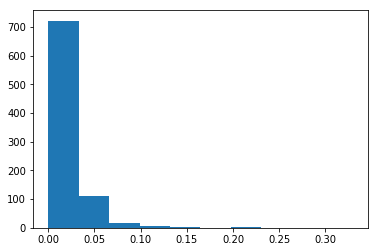

In [1021]:
plt.hist(df_flags.HR_error)

In [815]:
np.mean(df_flags.algo_accuracy)

0.9479048697621744

### debugging

In [972]:
#df_flags[~df_flags.patient_uuid.isin(d_patients)].algo_accuracy.mean()

0.9593425605536332

In [984]:
#df_flags[(~df_flags.patient_uuid.isin(d_patients)) & (df_flags.algo_accuracy < .7)]

,patient_uuid,HR_error,SBP_error,algo_accuracy,pred_rising_HR,actual_rising_HR,pred_lowering_HR,actual_lowering_HR,pred_rising_SBP,actual_rising_SBP,pred_high_BP,actual_high_BP,pred_min_HR,actual_min_HR,pred_max_HR,actual_max_HR,pred_min_SBP,actual_min_SBP,pred_max_SBP,actual_max_SBP
47,6080232,0.109279,0.218892,0.500,True,False,False,False,False,False,False,True,0,0,4,0,2,0,0,0
145,16197796,0.014620,0.071809,0.625,False,False,False,False,True,False,True,True,1,0,3,1,0,0,0,0
214,23285686,0.003801,0.233498,0.625,False,False,False,False,False,False,False,False,1,0,1,0,3,0,0,0
242,26760847,0.103092,0.214949,0.625,False,False,False,False,True,False,False,False,3,0,0,0,0,0,3,0
267,29451855,0.329438,0.475016,0.500,False,False,True,False,True,True,False,True,7,0,0,0,0,0,7,0
282,30915120,0.003145,0.061048,0.625,False,False,False,False,True,False,False,False,0,0,22,25,22,25,0,0
340,36398581,0.074332,0.090118,0.500,True,False,False,False,True,False,True,False,0,0,10,8,0,0,0,0
461,49237556,0.056857,0.163886,0.500,False,False,True,False,False,True,False,False,3,0,0,0,2,0,0,0
574,63321792,0.251222,0.170474,0.500,False,False,True,False,False,False,False,False,2,0,6,10,3,0,0,0
575,63408357,0.032159,0.026548,0.625,False,False,False,False,True,False,True,True,2,0,0,0,0,0,1,0


Accuracy - Accuracy is the most intuitive performance measure and it is simply a ratio of correctly predicted observation to the total observations. One may think that, if we have high accuracy then our model is best. Yes, accuracy is a great measure but only when you have symmetric datasets where values of false positive and false negatives are almost same. Therefore, you have to look at other parameters to evaluate the performance of your model. For our model, we have got 0.803 which means our model is approx. 80% accurate.

Accuracy = TP+TN/TP+FP+FN+TN

Precision - Precision is the ratio of correctly predicted positive observations to the total predicted positive observations. The question that this metric answer is of all passengers that labeled as survived, how many actually survived? High precision relates to the low false positive rate. We have got 0.788 precision which is pretty good.

Precision = TP/TP+FP

Recall (Sensitivity) - Recall is the ratio of correctly predicted positive observations to the all observations in actual class - yes. The question recall answers is: Of all the passengers that truly survived, how many did we label? We have got recall of 0.631 which is good for this model as it’s above 0.5.

Recall = TP/TP+FN

F1 score - F1 Score is the weighted average of Precision and Recall. Therefore, this score takes both false positives and false negatives into account. Intuitively it is not as easy to understand as accuracy, but F1 is usually more useful than accuracy, especially if you have an uneven class distribution. Accuracy works best if false positives and false negatives have similar cost. If the cost of false positives and false negatives are very different, it’s better to look at both Precision and Recall. In our case, F1 score is 0.701.

F1 Score = 2*(Recall * Precision) / (Recall + Precision)

In [1044]:
#rising hr
tp_rising_HR = np.sum((df_flags.pred_rising_HR == True) & (df_flags.actual_rising_HR == True))
tn_rising_HR = np.sum((df_flags.pred_rising_HR == False) & (df_flags.actual_rising_HR == False))
fp_rising_HR = np.sum((df_flags.pred_rising_HR == True) & (df_flags.actual_rising_HR == False))
fn_rising_HR = np.sum((df_flags.pred_rising_HR == False) & (df_flags.actual_rising_HR == True))

[tp_rising_HR, tn_rising_HR, fp_rising_HR, fn_rising_HR]


[3, 856, 6, 2]

In [1003]:
#lowering hr
tp_lowering_HR = np.sum((df_flags.pred_lowering_HR == True) & (df_flags.actual_lowering_HR == True))
tn_lowering_HR = np.sum((df_flags.pred_lowering_HR == False) & (df_flags.actual_lowering_HR == False))
fp_lowering_HR = np.sum((df_flags.pred_lowering_HR == True) & (df_flags.actual_lowering_HR == False))
fn_lowering_HR = np.sum((df_flags.pred_lowering_HR == False) & (df_flags.actual_lowering_HR == True))


[tp_lowering_HR, tn_lowering_HR, fp_lowering_HR, fn_lowering_HR]

[10, 848, 6, 3]

In [1006]:
#rising sbp
tp_rising_SBP = np.sum((df_flags.pred_rising_SBP == True) & (df_flags.actual_rising_SBP == True))
tn_rising_SBP = np.sum((df_flags.pred_rising_SBP == False) & (df_flags.actual_rising_SBP == False))
fp_rising_SBP = np.sum((df_flags.pred_rising_SBP == True) & (df_flags.actual_rising_SBP == False))
fn_rising_SBP = np.sum((df_flags.pred_rising_SBP == False) & (df_flags.actual_rising_SBP == True))

[tp_rising_SBP, tn_rising_SBP, fp_rising_SBP, fn_rising_SBP]


[55, 738, 39, 35]

In [1005]:
#high bp
tp_high_BP = np.sum((df_flags.pred_high_BP == True) & (df_flags.actual_high_BP == True))
tn_high_BP = np.sum((df_flags.pred_high_BP == False) & (df_flags.actual_high_BP == False))
fp_high_BP = np.sum((df_flags.pred_high_BP == True) & (df_flags.actual_high_BP == False))
fn_high_BP = np.sum((df_flags.pred_high_BP == False) & (df_flags.actual_high_BP == True))

[tp_high_BP, tn_high_BP, fp_high_BP, fn_high_BP]

[171, 664, 17, 15]

Accuracy = TP+TN/TP+FP+FN+TN
Precision = TP/TP+FP
Recall = TP/TP+FN
F1 Score = 2*(Recall * Precision) / (Recall + Precision)

In [1045]:
def accuracy_f1(true_positive, true_negative, false_positive, false_negative):
    """
    Calculates accuracy and F1-score for a particular feature.
    
    true_positive : number of true positives.
    true_negative : number of true negatives.
    false_positive: number of false positives.
    false_negative: number of false negatives.
    
    output:    acc: accuracy of the model on the feature.
          f1_score: F1-score of the model on the feature.
    """
    acc = (true_positive + true_negative) / (true_positive + false_positive + false_negative + true_negative)
    prec = true_positive / (true_positive + false_positive)
    rec = true_positive / (true_positive + false_negative)
    f1_score = 2 * (rec * prec) / (rec + prec)
    
    return acc, f1_score

In [1048]:
accuracy_f1(tp_rising_HR, tn_rising_HR, fp_rising_HR, fn_rising_HR)

(0.9907727797001153, 0.42857142857142855)

In [1049]:
accuracy_f1(tp_lowering_HR, tn_lowering_HR, fp_lowering_HR, fn_lowering_HR)

(0.9896193771626297, 0.6896551724137931)

In [1050]:
accuracy_f1(tp_rising_SBP, tn_rising_SBP, fp_rising_SBP, fn_rising_SBP)

(0.9146482122260668, 0.5978260869565217)

In [1051]:
accuracy_f1(tp_high_BP, tn_high_BP, fp_high_BP, fn_high_BP)

(0.9630911188004614, 0.9144385026737967)

In [1043]:
mae_min_HR = np.abs(df_flags.pred_min_HR - df_flags.actual_min_HR).mean()
mae_max_HR = np.abs(df_flags.pred_max_HR - df_flags.actual_max_HR).mean()
mae_min_SBP = np.abs(df_flags.pred_min_SBP - df_flags.actual_min_SBP).mean()
mae_max_SBP = np.abs(df_flags.pred_max_SBP - df_flags.actual_max_SBP).mean()

[mae_min_HR, mae_max_HR, mae_min_SBP, mae_max_SBP]

[0.15340253748558247,
 0.10149942329873125,
 0.05651672433679354,
 0.029988465974625143]

In [1052]:
#rising hr
tp_rising_HR = np.sum((df_flags.pred_rising_HR == True) & (df_flags.actual_rising_HR == True))
tn_rising_HR = np.sum((df_flags.pred_rising_HR == False) & (df_flags.actual_rising_HR == False))
fp_rising_HR = np.sum((df_flags.pred_rising_HR == True) & (df_flags.actual_rising_HR == False))
fn_rising_HR = np.sum((df_flags.pred_rising_HR == False) & (df_flags.actual_rising_HR == True))


#lowering hr
tp_lowering_HR = np.sum((df_flags.pred_lowering_HR == True) & (df_flags.actual_lowering_HR == True))
tn_lowering_HR = np.sum((df_flags.pred_lowering_HR == False) & (df_flags.actual_lowering_HR == False))
fp_lowering_HR = np.sum((df_flags.pred_lowering_HR == True) & (df_flags.actual_lowering_HR == False))
fn_lowering_HR = np.sum((df_flags.pred_lowering_HR == False) & (df_flags.actual_lowering_HR == True))

# rising sbp
tp_rising_SBP = np.sum((df_flags.pred_rising_SBP == True) & (df_flags.actual_rising_SBP == True))
tn_rising_SBP = np.sum((df_flags.pred_rising_SBP == False) & (df_flags.actual_rising_SBP == False))
fp_rising_SBP = np.sum((df_flags.pred_rising_SBP == True) & (df_flags.actual_rising_SBP == False))
fn_rising_SBP = np.sum((df_flags.pred_rising_SBP == False) & (df_flags.actual_rising_SBP == True))


# high_bp
tp_high_BP = np.sum((df_flags.pred_high_BP == True) & (df_flags.actual_high_BP == True))
tn_high_BP = np.sum((df_flags.pred_high_BP == False) & (df_flags.actual_high_BP == False))
fp_high_BP = np.sum((df_flags.pred_high_BP == True) & (df_flags.actual_high_BP == False))
fn_high_BP = np.sum((df_flags.pred_high_BP == False) & (df_flags.actual_high_BP == True))

# metrics for binary flags
acc_rising_HR, f1_rising_HR = accuracy_f1(tp_rising_HR, tn_rising_HR, fp_rising_HR, fn_rising_HR)
acc_lowering_HR, f1_lowering_HR = accuracy_f1(tp_lowering_HR, tn_lowering_HR, fp_lowering_HR, fn_lowering_HR)
acc_rising_SBP, f1_rising_SBP = accuracy_f1(tp_rising_SBP, tn_rising_SBP, fp_rising_SBP, fn_rising_SBP)
acc_high_BP, f1_high_BP = accuracy_f1(tp_high_BP, tn_high_BP, fp_high_BP, fn_high_BP)

# mae for numerical flags
mae_min_HR = np.abs(df_flags.pred_min_HR - df_flags.actual_min_HR).mean()
mae_max_HR = np.abs(df_flags.pred_max_HR - df_flags.actual_max_HR).mean()
mae_min_SBP = np.abs(df_flags.pred_min_SBP - df_flags.actual_min_SBP).mean()
mae_max_SBP = np.abs(df_flags.pred_max_SBP - df_flags.actual_max_SBP).mean()


algo_metrics = [acc_rising_HR, f1_rising_HR, acc_lowering_HR, f1_lowering_HR, acc_rising_SBP, f1_rising_SBP,
                acc_high_BP, f1_high_BP, mae_min_HR, mae_max_HR, mae_min_SBP, mae_max_SBP]

algo_metrics_index = ['acc_rising_HR', 'f1_rising_HR', 'acc_lowering_HR', 'f1_lowering_HR', 'acc_rising_SBP',
                      'f1_rising_SBP','acc_high_BP', 'f1_high_BP', 'mae_min_HR', 'mae_max_HR', 'mae_min_SBP',
                      'mae_max_SBP']

algo_metrics

[0.9907727797001153,
 0.42857142857142855,
 0.9896193771626297,
 0.6896551724137931,
 0.9146482122260668,
 0.5978260869565217,
 0.9630911188004614,
 0.9144385026737967,
 0.15340253748558247,
 0.10149942329873125,
 0.05651672433679354,
 0.029988465974625143]

# debugging

In [817]:
df_flags[df_flags.patient_uuid == 19441941]

,patient_uuid,HR_error,SBP_error,algo_accuracy,actual_rising_HR,actual_lowering_HR,actual_rising_SBP,actual_min_HR,actual_max_HR,actual_min_SBP,actual_max_SBP,actual_high_BP,pred_rising_HR,pred_lowering_HR,pred_rising_SBP,pred_min_HR,pred_max_HR,pred_min_SBP,pred_max_SBP,pred_high_BP
176,19441941,3.065016e+25,2.753197e+25,0.375,False,False,False,0,0,0,0,False,True,False,False,2,4,4,2,False


In [798]:
df_model[df_model.patient_uuid == 19441941]

,patient_uuid,HR_mape,HR_mae,HR_rsme,SBP_mape,SBP_mae,SBP_rsme
176,19441941,4.366557e+25,3.536804e+27,8.221280e+27,3.973140e+25,5.004383e+27,1.163294e+28


In [805]:
df_vitals[df_vitals.patient_uuid == 19441941].tail(30)

,patient_uuid,timestamp,batch,HR,SBP
22830,19441941,2019-12-14,0,79.526029,134.420074
22831,19441941,2019-12-15,0,79.577002,134.126864
22832,19441941,2019-12-16,0,79.627975,133.833653
22833,19441941,2019-12-17,0,79.678948,133.540442
22834,19441941,2019-12-18,0,79.729921,133.247231
22835,19441941,2019-12-19,0,79.780894,132.954020
22836,19441941,2019-12-20,0,79.831868,132.660809
22837,19441941,2019-12-21,0,79.882841,132.367598
22838,19441941,2019-12-22,0,79.933814,132.074387
22839,19441941,2019-12-23,0,79.984787,131.781176


In [854]:
df_vitals2[df_vitals2.patient_uuid == 19441941][['patient_uuid', 'timestamp', 'HR', 'SBP']].tail(30)

,patient_uuid,timestamp,HR,SBP
19118,19441941,2019-11-09,74.0,167.0
19119,19441941,2019-11-20,79.0,154.0
19120,19441941,2019-11-23,93.0,172.0
19121,19441941,2019-11-24,73.0,154.0
19122,19441941,2019-12-04,90.0,126.0
19123,19441941,2019-12-07,74.0,128.0
19124,19441941,2019-12-08,76.0,128.0
19125,19441941,2019-12-09,79.0,122.0
19126,19441941,2019-12-10,75.5,141.0
19127,19441941,2019-12-11,80.0,143.0


In [808]:
flags(df_vitals[df_vitals.patient_uuid == 19441941][-30:])

[patient_uuid    1.944194e+07
 batch           0.000000e+00
 HR              8.077487e+01
 SBP             1.272364e+02
 dtype: float64, False, False, False, 0, 0, 0, 0, False]

(array([  2.,   6.,   5.,   0.,   8.,   8.,   0.,  33., 171., 650.]),
 array([0.125 , 0.2125, 0.3   , 0.3875, 0.475 , 0.5625, 0.65  , 0.7375,
        0.825 , 0.9125, 1.    ]),
 <a list of 10 Patch objects>)

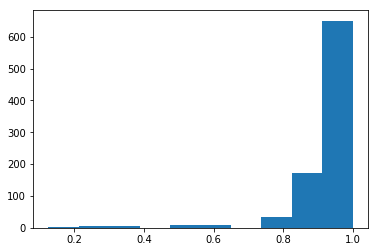

In [818]:
plt.hist(df_flags.algo_accuracy)

In [843]:
d_patients = list(df_model[df_model.HR_mape > 1].patient_uuid)

In [ ]:
#for debugging
#df_flags = df_flags[~df_flags.patient_uuid.isin(d_patients)]

In [841]:
df_vitals.head()

,patient_uuid,timestamp,batch,HR,SBP
0,1127912,2019-11-19,0,87.261064,124.85394
1,1127912,2019-11-20,0,92.000000,120.50000
2,1127912,2019-11-21,0,87.000000,131.75000
3,1127912,2019-11-22,0,89.000000,127.00000
4,1127912,2019-11-23,0,93.000000,109.50000


In [944]:
df_vitals[df_vitals.patient_uuid == d_patients[4]].tail(20)

,patient_uuid,timestamp,batch,HR,SBP
26125,20766826,2019-12-20,0,80.179078,130.670363
26126,20766826,2019-12-21,0,80.395802,130.308964
26127,20766826,2019-12-22,0,80.612526,129.947564
26128,20766826,2019-12-23,0,80.829250,129.586165
26129,20766826,2019-12-24,0,81.045974,129.224765
26130,20766826,2019-12-25,0,81.262698,128.863365
26131,20766826,2019-12-26,0,81.479422,128.501966
26132,20766826,2019-12-27,0,81.696146,128.140566
26133,20766826,2019-12-28,0,81.912869,127.779166
26134,20766826,2019-12-29,0,82.129593,127.417767


In [945]:
df_vitals2[df_vitals2.patient_uuid == d_patients[5]].tail(20)

,patient_uuid,timestamp,HR,SBP
22345,20766826,2019-11-25,77.0,137.5
22346,20766826,2019-12-08,77.0,142.0
22347,20766826,2019-12-13,75.5,130.5
22348,20766826,2019-12-16,78.0,121.0
22349,20766826,2019-12-18,82.0,136.0
22350,20766826,2019-12-21,80.0,124.0
22351,20766826,2019-12-30,88.0,126.0
22352,20766826,2020-01-04,101.0,120.0
22353,20766826,2020-01-06,87.0,125.0
22354,20766826,2020-01-08,74.0,128.0


In [946]:
len(d_patients)

16

In [949]:
aa.diff()

,HR,SBP
timestamp,,
2019-11-05,NaN,NaN
2019-11-06,0.632769,-0.188767
2019-11-07,2.453190,6.626860
2019-11-08,2.000000,-37.000000
2019-11-09,-2.554883,29.806840
2019-11-10,0.632769,-0.188767
2019-11-11,0.632769,-0.188767
2019-11-12,0.632769,-0.188767
2019-11-13,0.632769,-0.188767


In [970]:
df_model[~df_model.patient_uuid.isin(d_patients)].HR_mape.mean()

0.042874850869029923

In [971]:
df_model[~df_model.patient_uuid.isin(d_patients)].SBP_mape.mean()

0.04531010426288263